In [1]:
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_dev = os.path.join(pth_data, 'development', 'modeling')
pth_fig = os.path.join(pth, 'figures', 'CCCA')
pth_out = os.path.join(pth_data, 'results', 'classifier')

In [3]:
celltypes_train = [
    'Epiblast',
    'Posterior Epiblast',
    'Lateral Plate Mesoderm',
    'Neuromesodermal Progenitor',
    'Presomitic Mesoderm',
    'Premigratory Neural Crest',
    'Migratory Neural Crest',
    'Neuroglial Progenitors',
    'Cranial Mesenchyme']

In [4]:
adata = sc.read_h5ad(os.path.join(pth_dev, 'signatures.h5ad'))
adata = adata[adata.obs.celltype.isin(celltypes_train)].copy()
adata

AnnData object with n_obs × n_vars = 13029 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [5]:
adata_test = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata_test

AnnData object with n_obs × n_vars = 1406087 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [6]:
src_labels = {
    'GSE162534'         : 'Branch1',
    'GSE229103'         : 'Branch2',
    'rRNAModifications' : 'Branch2'}

In [7]:
# branch labels (counts)
adata.obs['branch'] = adata.obs.source.map(src_labels)
adata.obs.branch.value_counts()

branch
Branch1    7073
Branch2    5956
Name: count, dtype: int64

In [8]:
# train classifier (logistic regression)
X, y = adata.obs[src_labels.keys()].values, adata.obs.branch.values
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size = .2, random_state = 1, stratify = y)
logreg = LogisticRegression(penalty = None).fit(X_train, y_train)

# save model (betas)
df = pd.Series(logreg.coef_[0],
               index = src_labels.keys(),
               name = 'beta')
df.loc['intercept_'] = logreg.intercept_[0]
df.to_csv(os.path.join(pth_out, 'logreg.csv'))

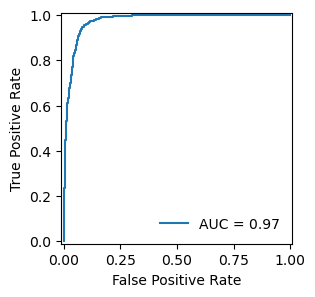

In [9]:
# validation split (predict)
pos_label, ix = 'Branch2', logreg.classes_
p_val = logreg.predict_proba(X_val)[:, ix == pos_label]
fpr, tpr, _ = roc_curve(y_val, p_val, pos_label = pos_label)
auc = roc_auc_score(y_val, p_val)

# plot performance (ROC)
fig, ax = plt.subplots(1, 1, figsize = (3, 3))
RocCurveDisplay(fpr = fpr, tpr = tpr, roc_auc = auc).plot(ax = ax)
ax.legend(loc = 4).set_frame_on(False)

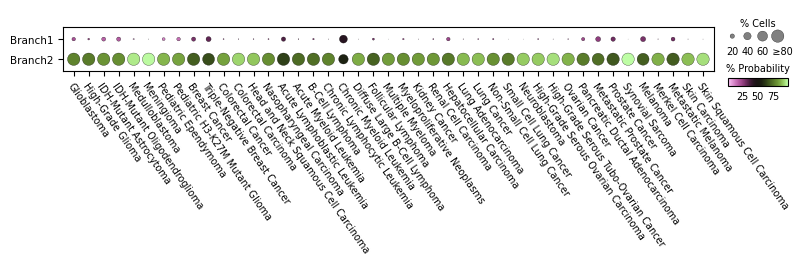

In [34]:
# predict 3CA (testing)
X_test = adata_test.obs[src_labels.keys()].values
p_test = logreg.predict_proba(X_test)
adata_test.obs[logreg.classes_] = p_test * 100
ix = (adata_test.obs.groupby(
      ['Category', 'Disease'], observed = True)
      .first().reset_index().Disease)

# probabilities dotplot
fs, var = 7, logreg.classes_
dp = sc.pl.dotplot(adata_test, var, 'Disease',
                   categories_order = ix,
                   expression_cutoff = 50,
                   dot_max = .8,
                   vcenter = 50,
                   cmap = 'vanimo',
                   figsize = (9.5, .575),
                   swap_axes = True,
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 80,
         x_padding = .7,
         y_padding = .6)
dp.legend(width = .8)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs, pad = -12)
ax_size.tick_params('x', size = 0, labelsize = fs, pad = .8)
ax_size.set_xticklabels(['20', '40', '60', '   ≥80'])
cax.set_title('% Probability', size = fs, pad = 4.5)
cax.tick_params('x', size = 0, labelsize = fs, pad = 4)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([.985 * pos_size.x0,
                      pos_main.y0 + .6 * pos_main.height,
                      pos_size.width,
                      .8 * pos_main.height])

cax.set_position([.985 * pos_color.x0,
                  pos_main.y0 - .33 * pos_main.height,
                  pos_color.width,
                  .185 * pos_main.height])

ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        rotation = -55, fontsize = fs,
                        rotation_mode = 'anchor',
                        ha = 'left')
ax_main.tick_params('y', labelsize = fs + .5)

fn = os.path.join(pth_fig, 'probabilities.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [11]:
adata_test.write(os.path.join(pth_in, 'probabilities.h5ad'))